# Experiment 07 — Balanced Batches on Simulated Imbalance

## Objective

This experiment studies how batch construction affects model performance under class imbalance.

Because the cleaned training data is not intentionally designed as a strongly imbalanced benchmark, we create a reproducible simulated imbalance from the cleaned training split.

We compare:

1. Standard mini-batches with `shuffle=True`
2. Balanced mini-batches using a custom `BalancedBatchSampler`

The validation and test sets remain unchanged.

### Evaluation metrics

We compare:

- Overall accuracy
- Macro-F1
- Per-class recall

The main question is whether balanced batches improve performance for underrepresented classes.

In [1]:
import sys
from pathlib import Path
from torchvision import datasets
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import math
from collections import Counter
import json
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from torch.optim import Adam
from torchvision import transforms
from torch.utils.data import Subset, DataLoader

from sklearn.metrics import classification_report

# Project root
PROJECT_DIR = Path.cwd().parent

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

sys.path.append("../src")

from data import (
    letterbox,
    create_train_val_datasets,
    create_dataloaders,
    BalancedBatchSampler,
    create_simulated_imbalance,
)

from models import SimpleCNN

from train import train_model

from utils import (
    get_predictions,
    plot_confusion_matrix,
    get_classification_report,
    plot_training_history,
    set_seed
)

### Configuration

In [2]:
SEED = 42
set_seed(SEED)
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 1e-3
NUM_CLASSES = 8

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cpu


### Paths

In [3]:
MERGED_TRAIN_DIR = PROJECT_DIR / "dataset" / "merged_train"


print("Training directory:", MERGED_TRAIN_DIR)


print("Training directory exists:", MERGED_TRAIN_DIR.exists())

Training directory: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\merged_train
Training directory exists: True


### Transforms as the Baseline Model

In [4]:
baseline_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: letterbox(
            img,
            target_size=(224, 224)
        )
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

### Creat Train/Validation Datasets

In [5]:
train_dataset, val_dataset, train_indices, val_indices,class_to_idx= \
    create_train_val_datasets(
        data_dir=MERGED_TRAIN_DIR,
        train_transform=baseline_transform,
        val_transform=baseline_transform,
        test_size=0.2,
        seed=SEED,
    )


print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Class mapping:", class_to_idx)

Training samples: 2712
Validation samples: 679
Class mapping: {'ambulance': 0, 'autobus': 1, 'kamyun': 2, 'kamyunet': 3, 'minibus': 4, 'savari': 5, 'taxi': 6, 'vanet': 7}


### Class Names and Labels

In [6]:
full_dataset = datasets.ImageFolder(
    MERGED_TRAIN_DIR,
    transform=baseline_transform
)

class_names = full_dataset.classes
class_to_idx = full_dataset.class_to_idx

print("Classes:")
for index, class_name in enumerate(class_names):
    print(index, "->", class_name)

print("\nNumber of classes:", len(class_names))

train_labels = np.array([
    full_dataset.targets[idx]
    for idx in train_indices
])
print (train_labels)

Classes:
0 -> ambulance
1 -> autobus
2 -> kamyun
3 -> kamyunet
4 -> minibus
5 -> savari
6 -> taxi
7 -> vanet

Number of classes: 8
[2 6 2 ... 6 1 5]


### Dataset Sizes

In [7]:
train_class_counts = Counter(
    full_dataset.targets[i]
    for i in train_indices
)

val_class_counts = Counter(
    full_dataset.targets[i]
    for i in val_indices
)

print("Class distribution:")
print()

for class_index, class_name in enumerate(class_names):
    train_count = train_class_counts[class_index]
    val_count = val_class_counts[class_index]

    print(
        f"{class_index} -> {class_name}: "
        f"Train = {train_count} ({train_count / len(train_dataset):.1%}), "
        f"Validation = {val_count} ({val_count / len(val_dataset):.1%})"
    )

print("Total training samples:", len(train_dataset) + len(val_dataset))
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Class distribution:

0 -> ambulance: Train = 289 (10.7%), Validation = 72 (10.6%)
1 -> autobus: Train = 376 (13.9%), Validation = 94 (13.8%)
2 -> kamyun: Train = 396 (14.6%), Validation = 100 (14.7%)
3 -> kamyunet: Train = 364 (13.4%), Validation = 91 (13.4%)
4 -> minibus: Train = 329 (12.1%), Validation = 82 (12.1%)
5 -> savari: Train = 400 (14.7%), Validation = 100 (14.7%)
6 -> taxi: Train = 394 (14.5%), Validation = 99 (14.6%)
7 -> vanet: Train = 164 (6.0%), Validation = 41 (6.0%)
Total training samples: 3391
Training samples: 2712
Validation samples: 679


### Create Simulated Imbalance

In [8]:
IMBALANCE_CLASSES = [
    "ambulance",
    "autobus",
    "kamyun",
]

RETAIN_FRACTION = 0.3

imbalanced_indices = create_simulated_imbalance(
    train_indices=train_indices,
    train_labels=train_labels,
    class_to_idx=class_to_idx,
    selected_classes=IMBALANCE_CLASSES,
    retain_fraction=RETAIN_FRACTION,
    seed=SEED
)

print(
    "Original training samples:",
    len(train_indices)
)

print(
    "Imbalanced training samples:",
    len(imbalanced_indices)
)

Original training samples: 2712
Imbalanced training samples: 1967


### Comparision Class Counts

In [9]:
idx_to_class = {
    idx: class_name
    for class_name, idx in class_to_idx.items()
}

In [10]:
def count_classes(indices, dataset):
    counts = {
        class_name: 0
        for class_name in class_to_idx
    }

    for idx in indices:
        label = dataset.targets[idx]
        class_name = idx_to_class[label]
        counts[class_name] += 1

    return counts

In [11]:
original_counts = count_classes(
    train_indices,
    full_dataset
)

imbalanced_counts = count_classes(
    imbalanced_indices,
    full_dataset
)


In [12]:
imbalance_comparison = pd.DataFrame({
    "Original Train": original_counts,
    "Simulated Imbalance": imbalanced_counts
})

imbalance_comparison

,Original Train,Simulated Imbalance
ambulance,289,86
autobus,376,112
kamyun,396,118
kamyunet,364,364
minibus,329,329
savari,400,400
taxi,394,394
vanet,164,164


### Retained Indices

In [13]:
retained_indices_report = {
    "seed": SEED,
    "selected_classes": IMBALANCE_CLASSES,
    "retain_fraction": RETAIN_FRACTION,
    "original_train_size": len(train_indices),
    "imbalanced_train_size": len(imbalanced_indices),
    "retained_indices": imbalanced_indices.tolist()
}

### Save Retained Indices

In [14]:
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

with open(
    RESULTS_DIR / "balanced_batch_retained_indices.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        retained_indices_report,
        f,
        indent=4
    )

### Create Inbalanced Train Dataset

In [15]:
imbalanced_dataset = Subset(
    full_dataset,
    imbalanced_indices
)

### Train/Validation Data Loaders

In [16]:
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

#### Run A — shuffle=True

In [17]:
#========================
# Run A — shuffle=True
#========================
standard_loader = DataLoader(
    imbalanced_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)



#### RUN B — BalancedBatchSampler

In [18]:
#==============================
# RUN B — BalancedBatchSampler
#==============================
imbalanced_labels = [
    full_dataset.targets[idx]
    for idx in imbalanced_indices
]

balanced_sampler = BalancedBatchSampler(
    labels=imbalanced_labels,
    batch_size=BATCH_SIZE,
    num_classes=NUM_CLASSES,
    seed=SEED
)

balanced_loader = DataLoader(
    imbalanced_dataset,
    batch_sampler=balanced_sampler,
    num_workers=0
)

### Checking BalancedBatchSampler

In [19]:
images, labels = next(iter(balanced_loader))

print("Batch shape:", images.shape)
print("Labels:", labels)

unique, counts = torch.unique(
    labels,
    return_counts=True
)

batch_distribution = dict(
    zip(
        unique.tolist(),
        counts.tolist()
    )
)

print("Class distribution:", batch_distribution)

Batch shape: torch.Size([32, 3, 224, 224])
Labels: tensor([4, 0, 7, 0, 5, 4, 5, 2, 1, 7, 1, 7, 4, 1, 5, 3, 1, 6, 6, 3, 3, 3, 7, 0,
        2, 2, 5, 0, 6, 6, 2, 4])
Class distribution: {0: 4, 1: 4, 2: 4, 3: 4, 4: 4, 5: 4, 6: 4, 7: 4}


### Model A — Standard Shuffle

In [20]:
set_seed(SEED)
model_standard = SimpleCNN(
    num_classes=NUM_CLASSES,
    dropout=0.0,
    use_gap=False
).to(DEVICE)

criterion_standard = torch.nn.CrossEntropyLoss()

optimizer_standard = torch.optim.AdamW(
    model_standard.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0
)

### Train Model A

In [21]:
history_standard, best_val_acc_standard = train_model(
    model=model_standard,
    train_loader=standard_loader,
    val_loader=val_loader,
    criterion=criterion_standard,
    optimizer=optimizer_standard,
    device=DEVICE,
    epochs=EPOCHS,
    model_name="balanced_batches_standard_shuffle",
    class_to_idx=class_to_idx,
    seed=SEED,
    config={
        "experiment": "balanced_batches",
        "sampling": "shuffle=True",
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "simulated_imbalance": True,
        "selected_classes": IMBALANCE_CLASSES,
        "retain_fraction": RETAIN_FRACTION
    }
)

Epoch [1/10] Train Loss: 2.5704 --- Train Acc: 0.4016 --- Val Loss: 1.3809 --- Val Acc: 0.5066 --- LR: 0.001000
Epoch [2/10] Train Loss: 0.8275 --- Train Acc: 0.7168 --- Val Loss: 0.8890 --- Val Acc: 0.6922 --- LR: 0.001000
Epoch [3/10] Train Loss: 0.4050 --- Train Acc: 0.8617 --- Val Loss: 0.9005 --- Val Acc: 0.7364 --- LR: 0.001000
Epoch [4/10] Train Loss: 0.2129 --- Train Acc: 0.9268 --- Val Loss: 0.9462 --- Val Acc: 0.7349 --- LR: 0.001000
Epoch [5/10] Train Loss: 0.0840 --- Train Acc: 0.9786 --- Val Loss: 1.1655 --- Val Acc: 0.7320 --- LR: 0.001000
Epoch [6/10] Train Loss: 0.0376 --- Train Acc: 0.9929 --- Val Loss: 1.3171 --- Val Acc: 0.7275 --- LR: 0.001000
Epoch [7/10] Train Loss: 0.0190 --- Train Acc: 0.9959 --- Val Loss: 1.3503 --- Val Acc: 0.7275 --- LR: 0.001000
Epoch [8/10] Train Loss: 0.0229 --- Train Acc: 0.9939 --- Val Loss: 1.5739 --- Val Acc: 0.7010 --- LR: 0.001000
Epoch [9/10] Train Loss: 0.0366 --- Train Acc: 0.9914 --- Val Loss: 1.4880 --- Val Acc: 0.7128 --- LR: 0

### Model B — Balanced Batch

In [22]:
set_seed(SEED)
model_balanced = SimpleCNN(
    num_classes=NUM_CLASSES,
    dropout=0.0,
    use_gap=False
).to(DEVICE)

criterion_balanced = torch.nn.CrossEntropyLoss()

optimizer_balanced = torch.optim.AdamW(
    model_balanced.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0
)

### Train Model B

In [23]:
history_balanced, best_val_acc_balanced = train_model(
    model=model_balanced,
    train_loader=balanced_loader,
    val_loader=val_loader,
    criterion=criterion_balanced,
    optimizer=optimizer_balanced,
    device=DEVICE,
    epochs=EPOCHS,
    model_name="balanced_batches_sampler",
    class_to_idx=class_to_idx,
    seed=SEED,
    config={
        "experiment": "balanced_batches",
        "sampling": "BalancedBatchSampler",
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "simulated_imbalance": True,
        "selected_classes": IMBALANCE_CLASSES,
        "retain_fraction": RETAIN_FRACTION
    }
)

Epoch [1/10] Train Loss: 2.3260 --- Train Acc: 0.3596 --- Val Loss: 1.3304 --- Val Acc: 0.5493 --- LR: 0.001000
Epoch [2/10] Train Loss: 0.9065 --- Train Acc: 0.7059 --- Val Loss: 1.2396 --- Val Acc: 0.6082 --- LR: 0.001000
Epoch [3/10] Train Loss: 0.4793 --- Train Acc: 0.8448 --- Val Loss: 1.4528 --- Val Acc: 0.6289 --- LR: 0.001000
Epoch [4/10] Train Loss: 0.2823 --- Train Acc: 0.9139 --- Val Loss: 1.4212 --- Val Acc: 0.6333 --- LR: 0.001000
Epoch [5/10] Train Loss: 0.1898 --- Train Acc: 0.9452 --- Val Loss: 1.8453 --- Val Acc: 0.6406 --- LR: 0.001000
Epoch [6/10] Train Loss: 0.0967 --- Train Acc: 0.9739 --- Val Loss: 1.7183 --- Val Acc: 0.6348 --- LR: 0.001000
Epoch [7/10] Train Loss: 0.0724 --- Train Acc: 0.9816 --- Val Loss: 1.6913 --- Val Acc: 0.6686 --- LR: 0.001000
Epoch [8/10] Train Loss: 0.0516 --- Train Acc: 0.9841 --- Val Loss: 1.8848 --- Val Acc: 0.6495 --- LR: 0.001000
Epoch [9/10] Train Loss: 0.0313 --- Train Acc: 0.9939 --- Val Loss: 2.3916 --- Val Acc: 0.6362 --- LR: 0

### Training Curves

#### Standard Shuffle

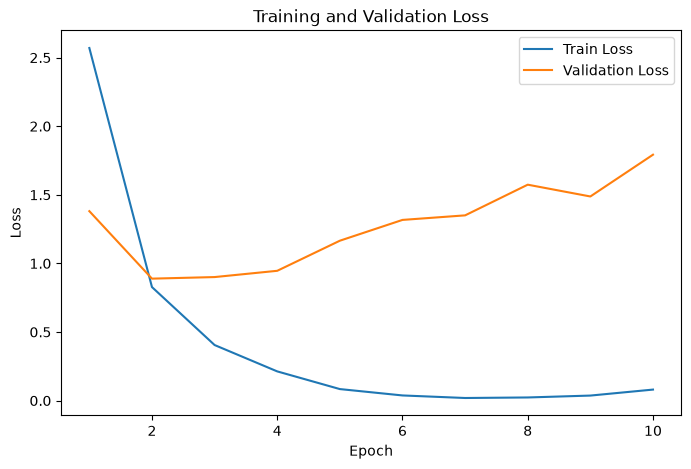

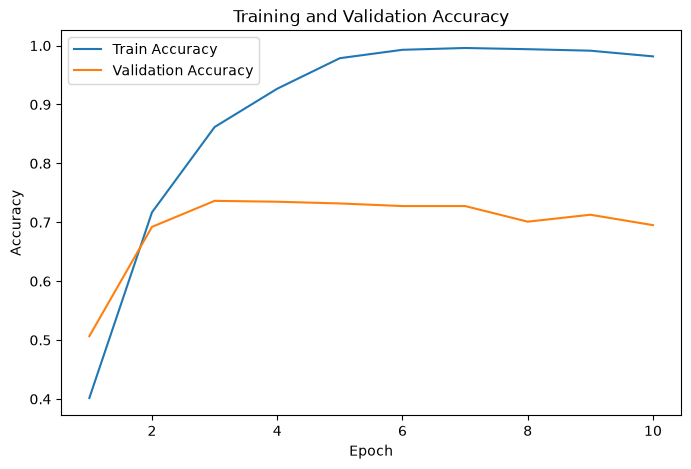

In [24]:
plot_training_history(history_standard)

#### Balanced Batch

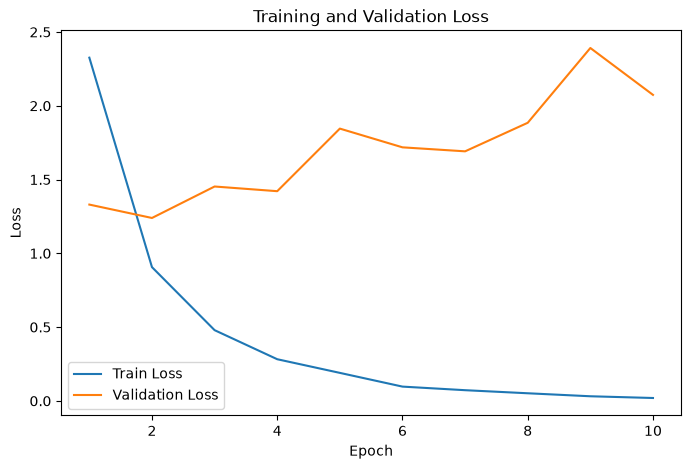

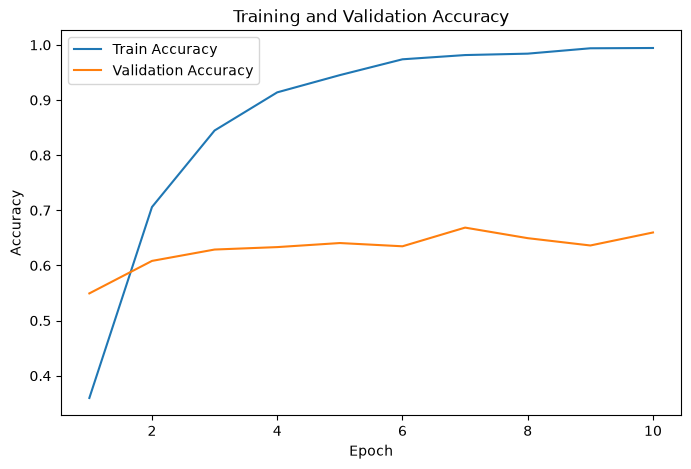

In [25]:
plot_training_history(history_balanced)

### Get Prediction

#### Standard Shuffle

In [26]:
best_epoch_standard = np.argmax(
    history_standard["val_accuracy"]
) + 1

print("Best epoch:", best_epoch_standard)
print("Best validation accuracy:", best_val_acc_standard)

Best epoch: 3
Best validation accuracy: 0.7363770250368189


#### Balanced Batch

In [27]:
best_epoch_balanced = np.argmax(
    history_balanced["val_accuracy"]
) + 1

print("Best epoch:", best_epoch_balanced)
print("Best validation accuracy:", best_val_acc_balanced)

Best epoch: 7
Best validation accuracy: 0.6686303387334315


### Load Best CheckPoint

In [28]:
#========================
# Run A — shuffle=True
#========================
standard_checkpoint_path = (
    PROJECT_DIR
    / "checkpoints"
    / "balanced_batches_standard_shuffle_best.pt"
)


standard_checkpoint = torch.load(
    standard_checkpoint_path,
    map_location=DEVICE
)

model_standard.load_state_dict(
    standard_checkpoint["model_state_dict"]
)

print("Standard Shuffle")
print("Best epoch:", standard_checkpoint["epoch"])
print(
    "Best validation accuracy:",
    standard_checkpoint["val_accuracy"]
)
print ("*"*30)

#==============================
# RUN B — BalancedBatchSampler
#==============================

balanced_checkpoint_path = (
    PROJECT_DIR
    / "checkpoints"
    / "balanced_batches_sampler_best.pt"
)


balanced_checkpoint = torch.load(
    balanced_checkpoint_path,
    map_location=DEVICE
)

model_balanced.load_state_dict(
    balanced_checkpoint["model_state_dict"]
)

print("Balanced Batch Loader")
print("Best epoch:", balanced_checkpoint["epoch"])
print(
    "Best validation accuracy:",
    balanced_checkpoint["val_accuracy"]
)

Standard Shuffle
Best epoch: 3
Best validation accuracy: 0.7363770250368189
******************************
Balanced Batch Loader
Best epoch: 7
Best validation accuracy: 0.6686303387334315


### Validation Prediction

In [29]:
# =================
# Standard Shuffle
# =================

true_labels_standard, prediction_standard = get_predictions(
    model_standard,
    val_loader,
    DEVICE
)

print ("Standard Shuffle")
print("Number of  validation predictions:", len(prediction_standard))
correct = (true_labels_standard == prediction_standard).sum()
print("Number of correct validation predictions:", correct)
accuracy = correct / len(prediction_standard)
print("Validation accuracy:", accuracy)
print ("="*30)
# =================
# Balanced Batch
# =================

true_labels_balanced, prediction_balanced = get_predictions(
    model_balanced,
    val_loader,
    DEVICE
)

print ("Balanced Batch Loader")
print("Number of  validation predictions:", len(prediction_balanced))
correct = (true_labels_balanced == prediction_balanced).sum()
print("Number of correct validation predictions:", correct)
accuracy = correct / len(prediction_balanced)
print("Validation accuracy:", accuracy)



Standard Shuffle
Number of  validation predictions: 679
Number of correct validation predictions: 500
Validation accuracy: 0.7363770250368189
Balanced Batch Loader
Number of  validation predictions: 679
Number of correct validation predictions: 454
Validation accuracy: 0.6686303387334315


### Classification Report

In [30]:
print ("Standard Shuffle")
report_standard = get_classification_report(
    model=model_standard,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE,
)

print ("="*30)

print ("Balanced Batch")
report_balanced = get_classification_report(
    model=model_balanced,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE,
)

Standard Shuffle
              precision    recall  f1-score   support

   ambulance     0.8298    0.5417    0.6555        72
     autobus     0.9595    0.7553    0.8452        94
      kamyun     0.6623    0.5100    0.5763       100
    kamyunet     0.5455    0.7912    0.6457        91
     minibus     0.7241    0.7683    0.7456        82
      savari     0.8252    0.8500    0.8374       100
        taxi     0.9490    0.9394    0.9442        99
       vanet     0.4262    0.6341    0.5098        41

    accuracy                         0.7364       679
   macro avg     0.7402    0.7238    0.7200       679
weighted avg     0.7646    0.7364    0.7397       679

Balanced Batch
              precision    recall  f1-score   support

   ambulance     0.8519    0.6389    0.7302        72
     autobus     0.8026    0.6489    0.7176        94
      kamyun     0.6364    0.3500    0.4516       100
    kamyunet     0.5093    0.6044    0.5528        91
     minibus     0.6000    0.8049    0.6875   

### Confusion Matrix and Normalized Confusion Matrix

Standard Suffle


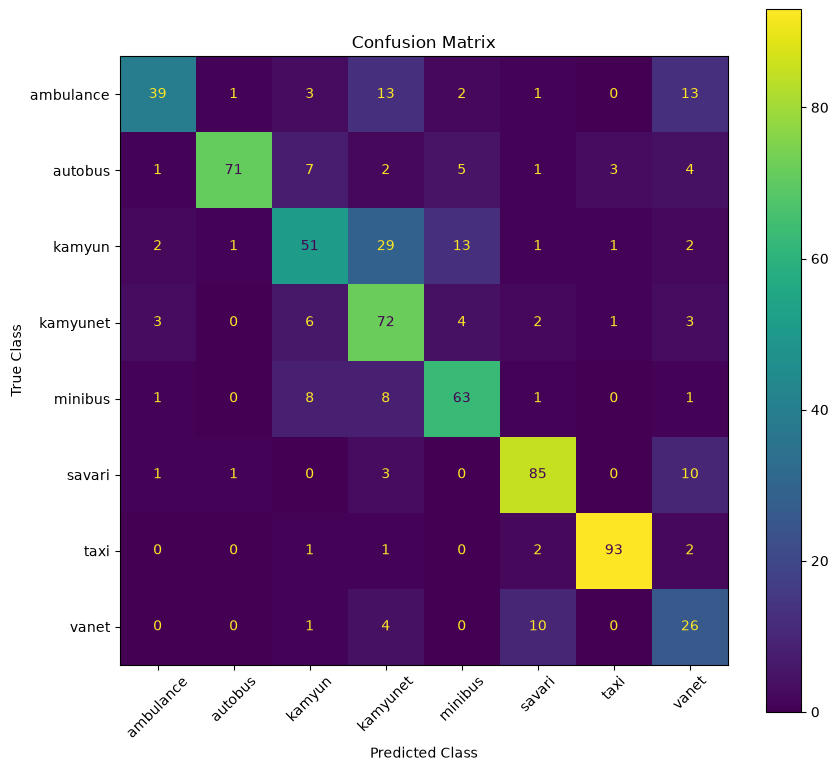

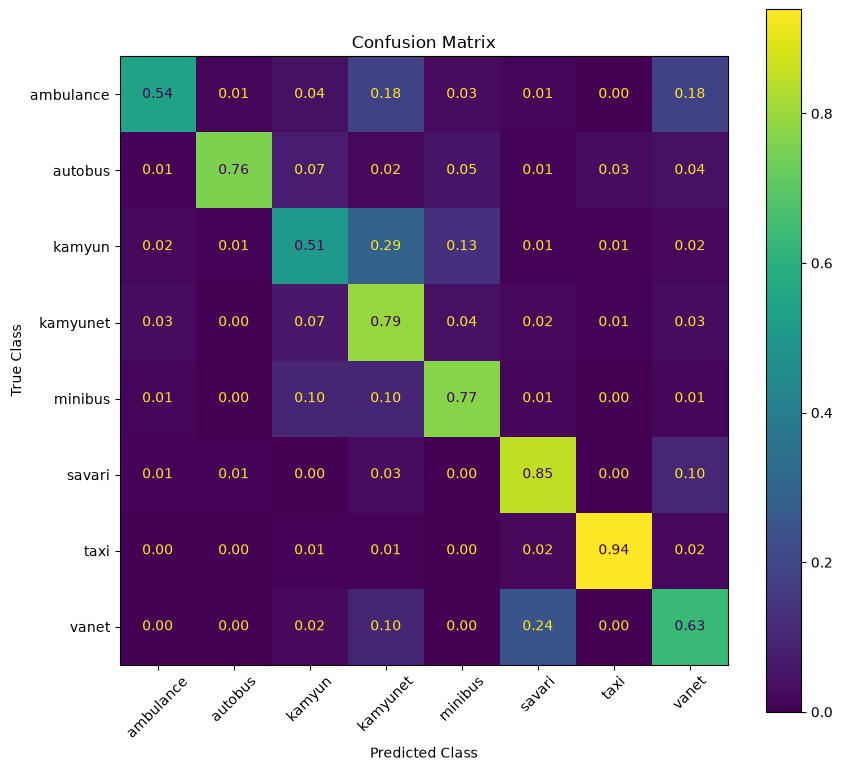

Balanced Batch


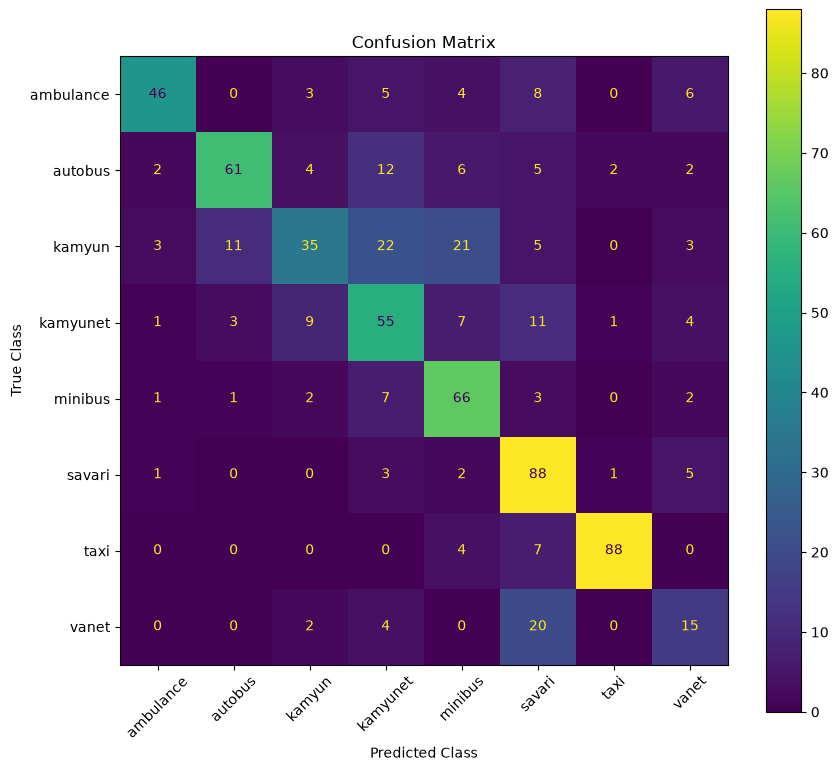

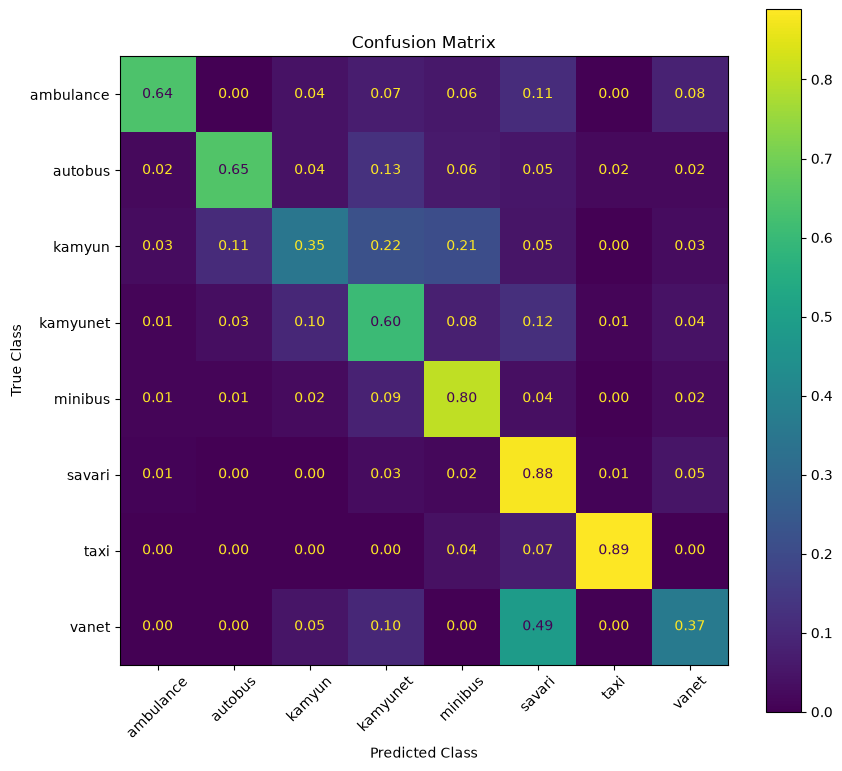

In [31]:
print ("Standard Suffle")
cm = plot_confusion_matrix(
    model=model_standard,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE
)
cm_normalized = plot_confusion_matrix(
    model=model_standard,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE,
    normalize="true"
)

print ("="*30)

print ("Balanced Batch")
cm = plot_confusion_matrix(
    model=model_balanced,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE
)
cm_normalized = plot_confusion_matrix(
    model=model_balanced,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE,
    normalize="true"
)


### Metrics Comparision 

In [35]:
f1_standard = f1_score(
    true_labels_standard,
    prediction_standard,
    average="macro",
    zero_division=0
)

f1_balanced = f1_score(
    true_labels_balanced,
    prediction_balanced,
    average="macro",
    zero_division=0
)

#========================

recall_standard = recall_score(
    true_labels_standard,
    prediction_standard,
    average="macro",
    zero_division=0
)

recall_balanced = recall_score(
    true_labels_balanced,
    prediction_balanced,
    average="macro",
    zero_division=0
)

#========================

acc_standard = accuracy_score(
    true_labels_standard,
    prediction_standard,
)

acc_balanced = accuracy_score(
    true_labels_balanced,
    prediction_balanced,
)
#==========================

precision_standard = precision_score(
    true_labels_standard,
    prediction_standard,
    average="macro",
    zero_division=0
)

precision_balanced = precision_score(
    true_labels_balanced,
    prediction_balanced,
    average="macro",
    zero_division=0
)


#==========================
print ("Standard Suffle ")
print("---------------------------")
print("Accuracy:", acc_standard)
print("Macro Precision:", precision_standard)
print("Macro Recall:", recall_standard)
print("Macro F1:", f1_standard)

print ("="*30)

print ("Balanced Batch Sampler")
print("---------------------------")
print("Accuracy:", acc_balanced)
print("Macro Precision:", precision_balanced)
print("Macro Recall:", recall_balanced)
print("Macro F1:", f1_balanced)


Standard Suffle 
---------------------------
Accuracy: 0.7363770250368189
Macro Precision: 0.7402035813510952
Macro Recall: 0.7237534463244764
Macro F1: 0.7199597861007887
Balanced Batch Sampler
---------------------------
Accuracy: 0.6686303387334315
Macro Precision: 0.6700841158425337
Macro Recall: 0.6477301574629026
Macro F1: 0.6447893089740956
